# Week 2: Choosing the model and choosing W

**Author:** Dr. Ummara Razi
Center for Sustainable Development and Green Innovation Research, Bahçeşehir Cyprus University, Nicosia, TRNC, Mersin 10, Turkey
Institute of Energy Policy and Research (IEPRe), UNITEN Business School, Universiti Tenaga Nasional, Malaysia
[Website](https://ummararazi.github.io) · [ORCID 0000-0002-5981-5736](https://orcid.org/0000-0002-5981-5736) · [LinkedIn](https://www.linkedin.com/in/dr-ummara-razi-45919752/)

**Note:** a *county* is a local administrative district inside a US state (similar to a district within a province), not a country. All data come from one country, the United States, divided into about 3,100 counties.

---

Week 1 showed that home values cluster strongly in space and that the spatial Durbin model (SDM) fits better than SAR or SEM. Week 2 asks the two questions every referee will ask next:

1. **Which spatial model?** Global spillovers (SDM) or local spillovers (SDEM and SLX)? And what about SAC?
2. **Which W?** Is "sharing a border" the right definition of a neighbour, or should it be distance, a fixed number of neighbours, or something institutional such as belonging to the same state?

We then add two things that make results credible in applied work:

3. **Fixed effects** to absorb regional factors that W would otherwise pick up.
4. **Robust inference**: heteroskedasticity-robust GMM and spatial HAC (Conley-type) standard errors.

**Same practice model as Week 1:** ln(median home value) on ln(median household income), ln(population density) and the share of homes heated by electricity. This is a teaching model chosen for clarity, not a research claim.

**Before you start:** this notebook reads the sample saved by Week 1 (`outputs/county_sample_week1.gpkg`). On Google Colab, create a folder called `outputs` and upload that file into it first. No Census API key is needed this week.

**Runtime:** about 5 to 10 minutes. Section 5 estimates around 30 maximum-likelihood models.

## 0. Setup

In [1]:
# Uncomment and run once if packages are missing (for example on Google Colab)
# %pip install geopandas libpysal esda spreg mapclassify matplotlib scipy

In [2]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import libpysal
from libpysal.weights import W, KNN, DistanceBand, Kernel
from libpysal.weights.util import attach_islands
import spreg

warnings.filterwarnings('ignore', category=UserWarning)     # libpysal connectivity notices
warnings.filterwarnings('ignore', category=RuntimeWarning)  # harmless divide-by-zero on W diagonals

OUT = 'outputs/week2'
os.makedirs(OUT, exist_ok=True)
np.random.seed(42)
print('Ready. Outputs will be saved to', OUT)

Ready. Outputs will be saved to outputs/week2


## 1. Load the Week 1 sample and build contiguity weights

We reuse the exact sample from Week 1, so results are directly comparable. Contiguity weights need the county polygons; every other W this week is built from county centroids.

In [5]:
import geopandas as gpd
from libpysal.weights import Queen, Rook

SAMPLE = 'outputs/county_sample_week1.gpkg'
# Check if the file is in the root directory if it's not in the outputs folder
if not os.path.exists(SAMPLE):
    if os.path.exists('county_sample_week1.gpkg'):
        SAMPLE = 'county_sample_week1.gpkg'
    else:
        raise FileNotFoundError(
            'outputs/county_sample_week1.gpkg not found. Run the Week 1 notebook first, '
            'or upload that file into an outputs/ folder next to this notebook.')

gdf = gpd.read_file(SAMPLE).to_crs(epsg=5070).reset_index(drop=True)
df = pd.DataFrame(gdf.drop(columns='geometry'))
cent = np.column_stack([gdf.geometry.centroid.x, gdf.geometry.centroid.y])   # metres

w_queen_raw = Queen.from_dataframe(gdf, use_index=False)
w_rook_raw = Rook.from_dataframe(gdf, use_index=False)
print('Counties:', len(df))

Counties: 3097


In [6]:
import pandas as pd
import numpy as np
import libpysal

# Ensure df is defined from the loaded gdf if it is missing
if 'df' not in globals() and 'gdf' in globals():
    df = pd.DataFrame(gdf.drop(columns='geometry'))

y_name = 'ln_homevalue'
x_names = ['ln_income', 'ln_density', 'elec_heat_share']
y = df[[y_name]].values
X = df[x_names].values
k = len(x_names)
N = len(df)


def finalize(w):
    # Connect islands to their nearest county, then row-standardise
    if w.islands:
        w = attach_islands(w, KNN(cent, k=1))
    w.transform = 'r'
    return w


def lagx(w, A):
    # Spatial lag of every column of A
    return np.column_stack([libpysal.weights.lag_spatial(w, A[:, j]) for j in range(A.shape[1])])


w_queen = finalize(w_queen_raw)
w_rook = finalize(w_rook_raw)
for name, w in [('Queen', w_queen), ('Rook', w_rook)]:
    print(f'{name:6s} mean neighbours = {w.mean_neighbors:.2f}, min = {w.min_neighbors}, max = {w.max_neighbors}')

Queen  mean neighbours = 5.85, min = 1, max = 14
Rook   mean neighbours = 5.64, min = 1, max = 13


## 2. The family of spatial models

Week 1 used four models. The full family has seven members, all nested in the General Nesting Spatial (GNS) model:

y = ρWy + Xβ + WXθ + u,  u = λWu + ε

| Model | ρ (Wy) | θ (WX) | λ (Wu) | Spillovers |
|---|---|---|---|---|
| OLS | 0 | 0 | 0 | None |
| SLX | 0 | free | 0 | **Local**: only from direct neighbours |
| SAR | free | 0 | 0 | Global, same ratio to direct effect for every X |
| SEM | 0 | 0 | free | None (nuisance only) |
| **SDM** | free | free | 0 | **Global**: ripple through the whole map |
| **SDEM** | 0 | free | free | **Local**, with spatially correlated errors |
| SAC | free | 0 | free | Global, plus correlated errors |
| GNS | free | free | free | Weakly identified in practice; rarely estimated |

The key choice in applied work is usually **SDM versus SDEM** (LeSage, 2014). The two differ in one economic assumption:

- **SDM (global):** a shock in county A reaches its neighbours, their neighbours, and so on, with feedback. Plausible when outcomes interact directly, such as house prices that respond to prices next door through buyer search and appraisals.
- **SDEM (local):** a change in A affects only A's immediate neighbours. Any wider correlation is in the errors (shared unobservables). Plausible when spillovers have a limited range, such as commuting or local public goods.

Statistics can tell us which model fits better, but the choice should start from the economic channel.

## 3. Estimate the whole family (Queen W)

In [7]:
def n_params(m):
    # Coefficients (including rho or lambda) plus the error variance
    return len(np.asarray(m.betas).flatten()) + 1


def aic(m):
    return -2 * m.logll + 2 * n_params(m)


def fit_family(y, X, w, x_names, D=None, d_names=None, method='full'):
    # Returns a dict of fitted models. D = extra controls that are NOT spatially lagged (e.g. fixed effects)
    WX = lagx(w, X)
    wx_names = ['W_' + n for n in x_names]
    XWX = np.hstack([X, WX])
    names_x, names_xwx = list(x_names), list(x_names) + wx_names
    if D is not None:
        X = np.hstack([X, D])
        XWX = np.hstack([XWX, D])
        names_x, names_xwx = names_x + list(d_names), names_xwx + list(d_names)
    m = {}
    m['OLS'] = spreg.OLS(y, X, name_x=names_x)
    m['SLX'] = spreg.OLS(y, XWX, name_x=names_xwx)
    m['SAR'] = spreg.ML_Lag(y, X, w=w, method=method, name_x=names_x)
    m['SEM'] = spreg.ML_Error(y, X, w=w, method=method, name_x=names_x)
    m['SDM'] = spreg.ML_Lag(y, XWX, w=w, method=method, name_x=names_xwx)
    m['SDEM'] = spreg.ML_Error(y, XWX, w=w, method=method, name_x=names_xwx)
    return m


t0 = time.time()
models = fit_family(y, X, w_queen, x_names)
print(f'Six ML/OLS models estimated in {time.time() - t0:.1f} seconds')

ML_Lag
ML_Error
ML_Lag
ML_Error
Six ML/OLS models estimated in 79.2 seconds


In [8]:
# SAC (lag + error) has no ML estimator in spreg; we use GMM (Kelejian and Prucha)
sac = spreg.GM_Combo(y, X, w=w_queen, w_lags=2, name_x=x_names)
b_sac = np.asarray(sac.betas).flatten()
rho_sac, lam_sac = b_sac[-2], b_sac[-1]
se_rho_sac = np.sqrt(sac.vm[-1, -1])   # vm covers coefficients and rho, not lambda
print(f'SAC (GMM): rho = {rho_sac:.4f} (se {se_rho_sac:.4f}), lambda = {lam_sac:.4f}')

GM_Combo
SAC (GMM): rho = 0.2599 (se 0.0247), lambda = 0.5828


In [9]:
def coef_table(models, x_names):
    rows = []
    for name, m in models.items():
        b = np.asarray(m.betas).flatten()
        se = np.sqrt(np.diag(m.vm))
        labels = list(m.name_x)[:len(b)]
        if name in ('SAR', 'SDM'):
            labels[-1] = 'rho'
        if name in ('SEM', 'SDEM'):
            labels[-1] = 'lambda'
        for lab, bi, si in zip(labels, b, se):
            p = 2 * (1 - stats.norm.cdf(abs(bi / si)))
            star = '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.1 else ''
            rows.append({'model': name, 'term': lab, 'cell': f'{bi:.4f}{star} ({si:.4f})'})
    tab = pd.DataFrame(rows).pivot(index='term', columns='model', values='cell')
    order = ['CONSTANT'] + x_names + ['W_' + n for n in x_names] + ['rho', 'lambda']
    tab = tab.reindex([t for t in order if t in tab.index] + [t for t in tab.index if t not in order])
    tab = tab[[c for c in ['OLS', 'SLX', 'SAR', 'SEM', 'SDM', 'SDEM'] if c in tab.columns]]
    tab.loc['Log-likelihood'] = {k_: f'{m.logll:.2f}' for k_, m in models.items()}
    tab.loc['AIC'] = {k_: f'{aic(m):.2f}' for k_, m in models.items()}
    tab.loc['Parameters'] = {k_: str(n_params(m)) for k_, m in models.items()}
    return tab.fillna('')


coef_tab = coef_table(models, x_names)
coef_tab.to_csv(f'{OUT}/table_family_queen.csv')
coef_tab

model,OLS,SLX,SAR,SEM,SDM,SDEM
term,,,,,,
CONSTANT,-3.1484*** (0.2732),-6.4804*** (0.3641),-4.4828*** (0.1838),0.6936*** (0.2218),-1.5208*** (0.2302),-3.5257*** (0.6795)
ln_income,1.3597*** (0.0248),1.0481*** (0.0340),0.7789*** (0.0209),1.0031*** (0.0202),0.9850*** (0.0204),1.0447*** (0.0213)
ln_density,0.0519*** (0.0035),0.0693*** (0.0057),0.0243*** (0.0025),0.0763*** (0.0033),0.0741*** (0.0034),0.0703*** (0.0034)
elec_heat_share,0.1426*** (0.0241),0.1839*** (0.0670),0.1522*** (0.0163),0.1683*** (0.0364),0.2120*** (0.0403),0.2049*** (0.0368)
W_ln_income,,0.6155*** (0.0458),,,-0.6479*** (0.0333),0.3495*** (0.0523)
W_ln_density,,-0.0411*** (0.0070),,,-0.0685*** (0.0042),-0.0195** (0.0080)
W_elec_heat_share,,0.0732 (0.0723),,,-0.1578*** (0.0435),-0.0775 (0.0663)
rho,,,0.6483*** (0.0117),,0.8144*** (0.0122),
lambda,,,,0.8383*** (0.0113),,0.8205*** (0.0121)


**How to read this table.** Coefficients on X and WX in SDM are not marginal effects (Week 1, Section 6). Only in OLS, SLX and SDEM can β and θ be read directly, because those models have no ρWy feedback loop. Compare log-likelihoods and AIC across columns: higher log-likelihood and lower AIC indicate better fit, with AIC penalising extra parameters. Here AIC counts the error variance as a parameter in every model, so values are 2 higher than in Week 1, but the ranking is unchanged.

## 4. Testing between models

### 4.1 Nested comparisons (likelihood-ratio tests)

Each test compares a general model with a restricted version of itself. LR = 2 × (logL general − logL restricted), compared with a χ² distribution with degrees of freedom equal to the number of restrictions.

In [10]:
def lr_test(general, restricted, df_, label):
    s = 2 * (models[general].logll - models[restricted].logll)
    return {'Test': label, 'General': general, 'Restricted': restricted,
            'LR': s, 'df': df_, 'p-value': 1 - stats.chi2.cdf(s, df_)}


lr_tab = pd.DataFrame([
    lr_test('SDM', 'SAR', k, 'theta = 0 (no WX)'),
    lr_test('SDM', 'SLX', 1, 'rho = 0 (no Wy)'),
    lr_test('SDM', 'SEM', k, 'theta = -rho*beta (common factor)'),
    lr_test('SDEM', 'SEM', k, 'theta = 0 (no WX)'),
    lr_test('SDEM', 'SLX', 1, 'lambda = 0 (no spatial error)'),
    lr_test('SLX', 'OLS', k, 'theta = 0 (no WX)'),
])
lr_tab.to_csv(f'{OUT}/table_LR_nested.csv', index=False)
lr_tab.round(4)

,Test,General,Restricted,LR,df,p-value
0,theta = 0 (no WX),SDM,SAR,649.8600,3,0.0
1,rho = 0 (no Wy),SDM,SLX,2625.8789,1,0.0
2,theta = -rho*beta (common factor),SDM,SEM,60.3266,3,0.0
3,theta = 0 (no WX),SDEM,SEM,47.9089,3,0.0
4,lambda = 0 (no spatial error),SDEM,SLX,2613.4611,1,0.0
5,theta = 0 (no WX),SLX,OLS,184.8487,3,0.0


### 4.2 Non-nested comparison: SDM versus SDEM

SDM and SDEM are not nested, so no LR test applies. With the same number of parameters, compare log-likelihoods directly (equivalently, AIC). LeSage (2014) recommends this comparison, ideally across several W matrices, which we do in Section 5.

In [11]:
ll_sdm, ll_sdem = models['SDM'].logll, models['SDEM'].logll
print(f'SDM  log-likelihood = {ll_sdm:.2f}   AIC = {aic(models["SDM"]):.2f}')
print(f'SDEM log-likelihood = {ll_sdem:.2f}   AIC = {aic(models["SDEM"]):.2f}')
better = 'SDM' if ll_sdm > ll_sdem else 'SDEM'
print(f'With Queen W the data favour {better} by {abs(ll_sdm - ll_sdem):.2f} log-likelihood points.')

summary = pd.DataFrame({
    'logL': {k_: m.logll for k_, m in models.items()},
    'AIC': {k_: aic(m) for k_, m in models.items()},
    'params': {k_: n_params(m) for k_, m in models.items()},
}).sort_values('AIC')
summary.round(2)

SDM  log-likelihood = 741.17   AIC = -1464.34
SDEM log-likelihood = 734.96   AIC = -1451.92
With Queen W the data favour SDM by 6.21 log-likelihood points.


,logL,AIC,params
SDM,741.17,-1464.34,9
SDEM,734.96,-1451.92,9
SEM,711.01,-1410.01,6
SAR,416.24,-820.48,6
SLX,-571.77,1159.54,8
OLS,-664.19,1338.39,5


### 4.3 Effects under global and local spillovers

The real question is whether the **spillover estimates** change with the model, not which coefficient table looks nicer.

- **SDM:** direct and indirect effects come from (I − ρW)⁻¹(β + Wθ), with simulated inference (LeSage and Pace, 2009). The code is the same as Week 1.
- **SLX and SDEM:** no feedback loop, so the direct effect is β, the indirect effect is θ, and the total is β + θ. Standard errors follow directly from the coefficient covariance matrix.

In [12]:
def w_power_traces(w, P=100, R=50, seed=42):
    # tr(W^p)/N for p = 0..P+1: exact for p <= 2, Monte Carlo for higher powers
    Ws = w.sparse.tocsr()
    n = Ws.shape[0]
    rng = np.random.default_rng(seed)
    U = rng.choice([-1.0, 1.0], size=(n, R))
    tr = np.zeros(P + 2)
    tr[0], tr[1], tr[2] = n, Ws.diagonal().sum(), Ws.multiply(Ws.T).sum()
    V = Ws @ (Ws @ U)
    for p in range(3, P + 2):
        V = Ws @ V
        tr[p] = np.mean(np.sum(U * V, axis=0))
    return tr / n


def sdm_point(rho, beta, theta, trN):
    P = len(trN) - 2
    powers = rho ** np.arange(P + 1)
    direct = beta * np.sum(powers * trN[:P + 1]) + theta * np.sum(powers * trN[1:P + 2])
    total = (beta + theta) / (1 - rho)
    return direct, total - direct, total


def effects_lag(model, w, x_names, k, has_wx=True, n_draws=1000, seed=42):
    # Effects for SAR/SDM-type models (rho is the last coefficient)
    trN = w_power_traces(w)
    b = np.asarray(model.betas).flatten()
    V = np.asarray(model.vm)
    draws = np.random.default_rng(seed).multivariate_normal(b, V, size=n_draws)
    draws = draws[np.abs(draws[:, -1]) < 1]
    rows = []
    for j, name in enumerate(x_names):
        th = (lambda d: d[1 + k + j]) if has_wx else (lambda d: 0.0)
        point = sdm_point(b[-1], b[1 + j], th(b), trN)
        sims = np.array([sdm_point(d[-1], d[1 + j], th(d), trN) for d in draws])
        for e, lab in enumerate(['Direct', 'Indirect', 'Total']):
            se = sims[:, e].std()
            rows.append({'variable': name, 'effect': lab, 'estimate': point[e], 'se': se,
                         'p': 2 * (1 - stats.norm.cdf(abs(point[e] / se)))})
    return pd.DataFrame(rows)


def effects_local(model, x_names, k):
    # Effects for SLX/SDEM-type models: direct = beta, indirect = theta
    b = np.asarray(model.betas).flatten()
    V = np.asarray(model.vm)
    rows = []
    for j, name in enumerate(x_names):
        i_b, i_t = 1 + j, 1 + k + j
        parts = {'Direct': (b[i_b], V[i_b, i_b]),
                 'Indirect': (b[i_t], V[i_t, i_t]),
                 'Total': (b[i_b] + b[i_t], V[i_b, i_b] + V[i_t, i_t] + 2 * V[i_b, i_t])}
        for lab, (est, var) in parts.items():
            se = np.sqrt(var)
            rows.append({'variable': name, 'effect': lab, 'estimate': est, 'se': se,
                         'p': 2 * (1 - stats.norm.cdf(abs(est / se)))})
    return pd.DataFrame(rows)


def star(p):
    return '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.1 else ''


eff = {'SLX': effects_local(models['SLX'], x_names, k),
       'SDEM': effects_local(models['SDEM'], x_names, k),
       'SDM': effects_lag(models['SDM'], w_queen, x_names, k)}
eff_long = pd.concat([e.assign(model=m) for m, e in eff.items()])
eff_long['cell'] = [f'{r.estimate:.4f}{star(r.p)} ({r.se:.4f})' for r in eff_long.itertuples()]
eff_wide = eff_long.pivot_table(index=['variable', 'effect'], columns='model',
                                values='cell', aggfunc='first')[['SLX', 'SDEM', 'SDM']]
eff_long.to_csv(f'{OUT}/table_effects_by_model_long.csv', index=False)
eff_wide.to_csv(f'{OUT}/table_effects_by_model.csv')
eff_wide

model                                     SLX                SDEM  \
variable        effect                                              
elec_heat_share Direct     0.1839*** (0.0670)  0.2049*** (0.0368)   
                Indirect      0.0732 (0.0723)    -0.0775 (0.0663)   
                Total      0.2572*** (0.0266)    0.1275* (0.0688)   
ln_density      Direct     0.0693*** (0.0057)  0.0703*** (0.0034)   
                Indirect  -0.0411*** (0.0070)  -0.0195** (0.0080)   
                Total      0.0282*** (0.0042)  0.0507*** (0.0091)   
ln_income       Direct     1.0481*** (0.0340)  1.0447*** (0.0213)   
                Indirect   0.6155*** (0.0458)  0.3495*** (0.0523)   
                Total      1.6636*** (0.0331)  1.3942*** (0.0620)   

model                                     SDM  
variable        effect                         
elec_heat_share Direct     0.2164*** (0.0374)  
                Indirect      0.0758 (0.0904)  
                Total      0.2922*** (0.0853)  
ln_density      Direct     0.0717*** (0.0034)  
                Indirect  -0.0416*** (0.0132)  
                Total       0.0300** (0.0136)  
ln_income       Direct     1.0308*** (0.0207)  
                Indirect   0.7861*** (0.1025)  
                Total      1.8169*** (0.1064)

**What to look for.** Direct effects are usually similar across models. Indirect effects can differ a lot, because SDM lets spillovers travel through the whole network while SLX and SDEM stop at immediate neighbours. If your policy conclusion depends on the size of the spillover, this table is the one a referee will scrutinise.

## 5. Choosing W on economic grounds

### 5.1 Why "sharing a border" is not a neutral choice

US counties differ enormously in size. A county in Virginia may be 20 km across; one in Nevada may be 200 km across. Under Queen contiguity, "neighbour" therefore means something very different in the East and the West. The map and box plot below show the average distance from each county to its Queen neighbours.

            count  mean   50%    max
region                              
Midwest    1055.0  47.4  44.7  111.4
Northeast   209.0  48.2  46.7  152.0
South      1419.0  43.8  43.0  128.6
West        414.0  92.2  87.6  203.3


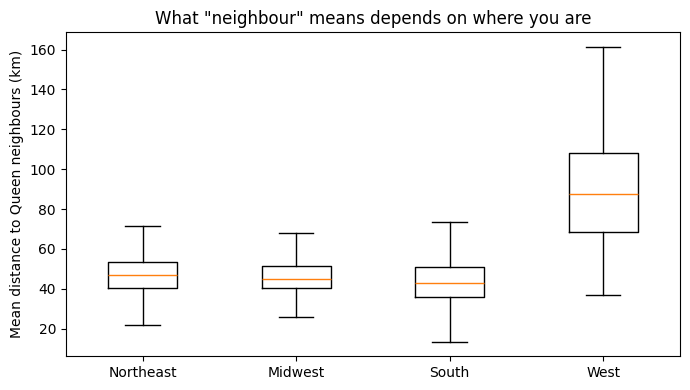

In [13]:
# Average centroid-to-centroid distance (km) between each county and its Queen neighbours
nb_dist = np.array([np.mean(np.linalg.norm(cent[list(w_queen.neighbors[i])] - cent[i], axis=1)) / 1000
                    for i in range(N)])
df['queen_nb_km'] = nb_dist

REGION = {
    'Northeast': ['09', '23', '25', '33', '34', '36', '42', '44', '50'],
    'Midwest': ['17', '18', '19', '20', '26', '27', '29', '31', '38', '39', '46', '55'],
    'South': ['01', '05', '10', '11', '12', '13', '21', '22', '24', '28', '37', '40', '45', '47', '48', '51', '54'],
    'West': ['04', '06', '08', '16', '30', '32', '35', '41', '49', '53', '56'],
}
fips_to_region = {f: r for r, fl in REGION.items() for f in fl}
df['region'] = df['STATEFP'].map(fips_to_region)

print(df.groupby('region')['queen_nb_km'].describe()[['count', 'mean', '50%', 'max']].round(1))

fig, ax = plt.subplots(figsize=(7, 4))
order = ['Northeast', 'Midwest', 'South', 'West']
ax.boxplot([df.loc[df['region'] == r, 'queen_nb_km'] for r in order], showfliers=False)
ax.set_xticks(range(1, 5))
ax.set_xticklabels(order)
ax.set_ylabel('Mean distance to Queen neighbours (km)')
ax.set_title('What "neighbour" means depends on where you are')
plt.tight_layout()
plt.savefig(f'{OUT}/fig_queen_distance_by_region.png', dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
gdf['queen_nb_km'] = df['queen_nb_km'].values
fig, ax = plt.subplots(figsize=(11, 6))
gdf.plot(column='queen_nb_km', cmap='viridis', legend=True, ax=ax, edgecolor='none',
         vmax=float(np.percentile(nb_dist, 98)),
         legend_kwds={'label': 'Mean distance to Queen neighbours (km)', 'shrink': 0.6})
ax.set_title('Distance to contiguous neighbours varies across the country')
ax.axis('off')
plt.savefig(f'{OUT}/fig_queen_distance_map.png', dpi=200, bbox_inches='tight')
plt.show()

### 5.2 Candidate W matrices and the economic channel each represents

| W | Rule | Economic story it fits |
|---|---|---|
| Queen / Rook contiguity | Share a border (Queen also counts corners) | Administrative adjacency; simple and conventional |
| k-nearest neighbours | The k closest counties | Equal number of contacts everywhere; distance varies |
| Distance band (binary) | All counties within d km, equal weights | A market or commuting range of about d km |
| Inverse distance | Weight = 1/distance^α within d km | Influence fades with distance; α sets how fast |
| Same state | All counties in the same state | Shared institutions: state taxes, regulation, utilities |

We estimate SDM and SDEM under each W and compare log-likelihoods. Because every model has the same number of parameters, a higher log-likelihood means a better fit.

**Two cautions.** A good fit does not make a W "true"; it is still an assumption. And very dense W matrices (large bands, the state block) tend to push ρ or λ towards 1, which is a sign that W is absorbing broad regional trends rather than local interaction.

In [14]:
def w_band(km):
    return finalize(DistanceBand(cent, threshold=km * 1000, binary=True, silence_warnings=True))


def w_invdist(km, alpha):
    return finalize(DistanceBand(cent, threshold=km * 1000, binary=False, alpha=-alpha, silence_warnings=True))


def w_state():
    groups = df.groupby('STATEFP').indices
    nb = {i: [j for j in groups[df.at[i, 'STATEFP']] if j != i] for i in range(N)}
    return finalize(W(nb, silence_warnings=True))


W_GRID = {'Queen': w_queen, 'Rook': w_rook}
for kk in [4, 6, 8, 12, 16]:
    W_GRID[f'KNN{kk}'] = finalize(KNN(cent, k=kk))
for km in [50, 100, 150, 200, 300]:
    W_GRID[f'Band{km}km'] = w_band(km)
W_GRID['InvDist150km_a1'] = w_invdist(150, 1)
W_GRID['InvDist150km_a2'] = w_invdist(150, 2)
W_GRID['SameState'] = w_state()

w_info = pd.DataFrame({name: {'mean_neighbours': w.mean_neighbors, 'min': w.min_neighbors,
                              'max': w.max_neighbors, 'islands_fixed': len(w.islands) == 0}
                       for name, w in W_GRID.items()}).T
w_info['mean_neighbours'] = w_info['mean_neighbours'].astype(float).round(1)
w_info

,mean_neighbours,min,max,islands_fixed
Queen,5.9,1,14,True
Rook,5.6,1,13,True
KNN4,4.0,4,4,True
KNN6,6.0,6,6,True
KNN8,8.0,8,8,True
KNN12,12.0,12,12,True
KNN16,16.0,16,16,True
Band50km,4.3,1,17,True
Band100km,17.7,1,48,True
Band150km,39.5,1,90,True


In [15]:
grid_rows = []
t0 = time.time()
for name, w in W_GRID.items():
    WX = lagx(w, X)
    XWX = np.hstack([X, WX])
    sdm = spreg.ML_Lag(y, XWX, w=w, method='full')
    sdem = spreg.ML_Error(y, XWX, w=w, method='full')
    e_sdm = effects_lag(sdm, w, x_names, k, n_draws=500)
    e_sdem = effects_local(sdem, x_names, k)
    pick = lambda e, v, f: e.loc[(e.variable == v) & (e.effect == f)].iloc[0]
    row = {'W': name, 'mean_nb': w.mean_neighbors,
           'logL_SDM': sdm.logll, 'logL_SDEM': sdem.logll,
           'rho_SDM': sdm.rho, 'lambda_SDEM': sdem.lam}
    for mod, e in [('SDM', e_sdm), ('SDEM', e_sdem)]:
        r_ = pick(e, 'ln_income', 'Indirect')
        row[f'income_indirect_{mod}'] = r_.estimate
        row[f'income_indirect_se_{mod}'] = r_.se
    grid_rows.append(row)
    print(f'{name:16s} logL SDM {sdm.logll:9.2f} | SDEM {sdem.logll:9.2f} | rho {sdm.rho:.3f} | lambda {sdem.lam:.3f}')
print(f'Done in {time.time() - t0:.0f} seconds')

grid = pd.DataFrame(grid_rows).set_index('W')
grid['best_model'] = np.where(grid['logL_SDM'] > grid['logL_SDEM'], 'SDM', 'SDEM')
grid['rho_near_1'] = grid['rho_SDM'] >= 0.95   # effects unreliable when rho is this close to 1
grid.to_csv(f'{OUT}/table_W_grid.csv')
grid.round(4)

ML_Lag
ML_Error
Queen            logL SDM    741.17 | SDEM    734.96 | rho 0.814 | lambda 0.820
ML_Lag
ML_Error
Rook             logL SDM    743.65 | SDEM    736.59 | rho 0.813 | lambda 0.819
ML_Lag
ML_Error
KNN4             logL SDM    645.05 | SDEM    633.19 | rho 0.775 | lambda 0.781
ML_Lag
ML_Error
KNN6             logL SDM    704.99 | SDEM    696.23 | rho 0.818 | lambda 0.825
ML_Lag
ML_Error
KNN8             logL SDM    740.93 | SDEM    735.24 | rho 0.844 | lambda 0.850
ML_Lag
ML_Error
KNN12            logL SDM    764.64 | SDEM    757.90 | rho 0.877 | lambda 0.885
ML_Lag
ML_Error
KNN16            logL SDM    764.87 | SDEM    760.15 | rho 0.895 | lambda 0.905
ML_Lag
ML_Error
Band50km         logL SDM    434.91 | SDEM    425.35 | rho 0.684 | lambda 0.687
ML_Lag
ML_Error
Band100km        logL SDM    711.35 | SDEM    712.21 | rho 0.854 | lambda 0.862
ML_Lag
ML_Error
Band150km        logL SDM    735.04 | SDEM    738.33 | rho 0.920 | lambda 0.927
ML_Lag
ML_Error
Band200km        logL SD

,mean_nb,logL_SDM,logL_SDEM,rho_SDM,lambda_SDEM,income_indirect_SDM,income_indirect_se_SDM,income_indirect_SDEM,income_indirect_se_SDEM,best_model,rho_near_1
W,,,,,,,,,,,
Queen,5.8502,741.1708,734.9619,0.8144,0.8205,0.7861,0.0984,0.3495,0.0523,SDM,False
Rook,5.6422,743.6487,736.5866,0.8126,0.8189,0.7767,0.0964,0.3378,0.0511,SDM,False
KNN4,4.0000,645.0527,633.1886,0.7753,0.7807,0.7253,0.0791,0.3150,0.0433,SDM,False
KNN6,6.0000,704.9934,696.2302,0.8180,0.8248,0.7932,0.1045,0.3243,0.0559,SDM,False
KNN8,8.0000,740.9265,735.2422,0.8438,0.8503,0.8254,0.1308,0.3371,0.0658,SDM,False
KNN12,12.0000,764.6427,757.9044,0.8773,0.8854,0.9184,0.1802,0.2642,0.0820,SDM,False
KNN16,16.0000,764.8677,760.1540,0.8954,0.9047,1.0162,0.2226,0.2522,0.0952,SDM,False
Band50km,4.2716,434.9125,425.3515,0.6842,0.6875,0.5962,0.0544,0.3096,0.0335,SDM,False
Band100km,17.7372,711.3550,712.2073,0.8538,0.8617,0.9854,0.1536,0.4206,0.0656,SDEM,False


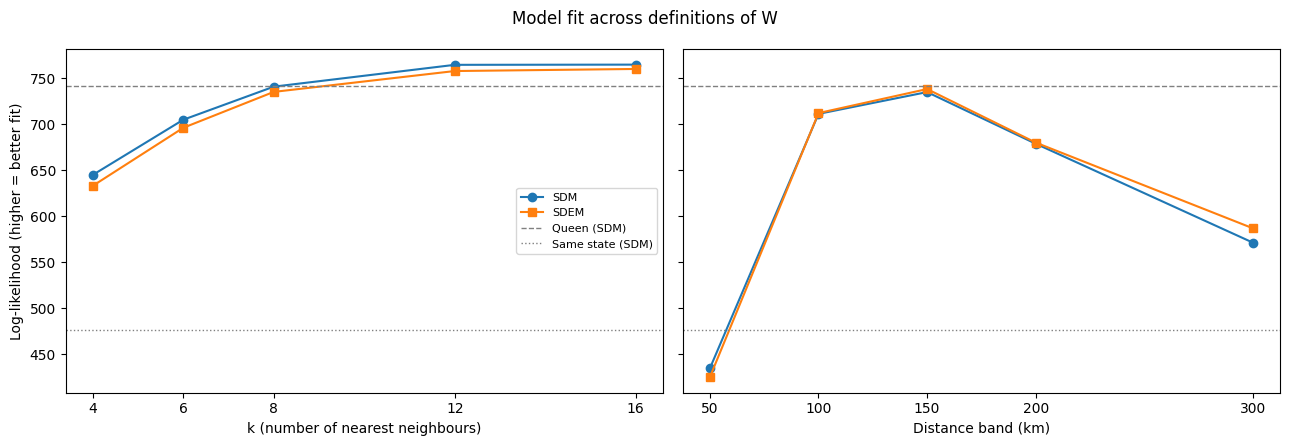

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
knn_names = [n for n in grid.index if n.startswith('KNN')]
band_names = [n for n in grid.index if n.startswith('Band')]
knn_x = [int(n[3:]) for n in knn_names]
band_x = [int(n[4:-2]) for n in band_names]

for ax, names, xs, xlabel in [(axes[0], knn_names, knn_x, 'k (number of nearest neighbours)'),
                              (axes[1], band_names, band_x, 'Distance band (km)')]:
    ax.plot(xs, grid.loc[names, 'logL_SDM'], marker='o', label='SDM')
    ax.plot(xs, grid.loc[names, 'logL_SDEM'], marker='s', label='SDEM')
    ax.axhline(grid.loc['Queen', 'logL_SDM'], color='grey', ls='--', lw=1, label='Queen (SDM)')
    ax.axhline(grid.loc['SameState', 'logL_SDM'], color='grey', ls=':', lw=1, label='Same state (SDM)')
    ax.set_xlabel(xlabel)
    ax.set_xticks(xs)
axes[0].set_ylabel('Log-likelihood (higher = better fit)')
axes[0].legend(fontsize=8)
fig.suptitle('Model fit across definitions of W')
plt.tight_layout()
plt.savefig(f'{OUT}/fig_fit_across_W.png', dpi=200, bbox_inches='tight')
plt.show()

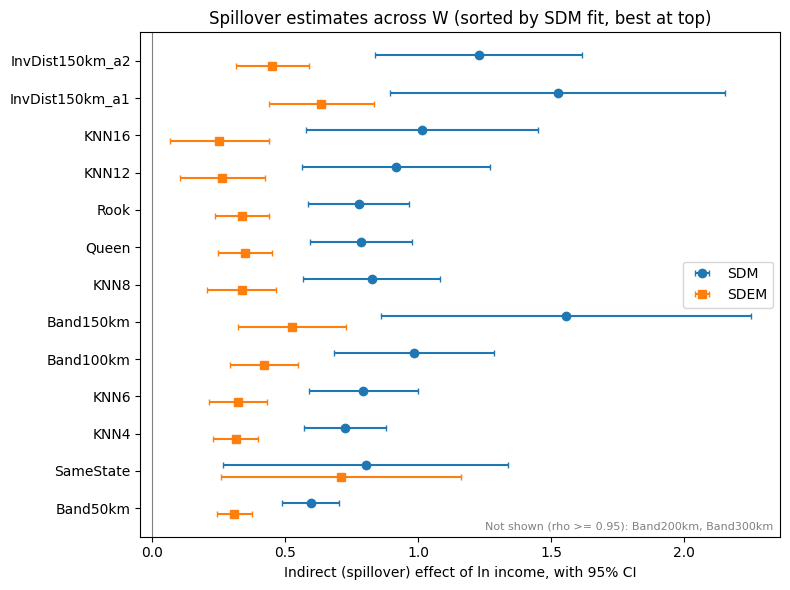

In [17]:
# How much does the income spillover depend on W and on the model?
# W matrices with rho >= 0.95 are left out: as rho approaches 1 the multiplier 1/(1 - rho)
# explodes and simulated SDM effects become meaningless (standard errors in the hundreds)
excluded = list(grid.index[grid['rho_near_1']])
order_w = grid[~grid['rho_near_1']].sort_values('logL_SDM', ascending=False).index
pos = np.arange(len(order_w))
fig, ax = plt.subplots(figsize=(8, 6))
for off, mod, mk in [(-0.15, 'SDM', 'o'), (0.15, 'SDEM', 's')]:
    est = grid.loc[order_w, f'income_indirect_{mod}']
    se = grid.loc[order_w, f'income_indirect_se_{mod}']
    ax.errorbar(est, pos + off, xerr=1.96 * se, fmt=mk, capsize=2, label=mod)
ax.axvline(0, color='grey', lw=0.8)
ax.set_yticks(pos)
ax.set_yticklabels(order_w)
ax.invert_yaxis()
ax.set_xlabel('Indirect (spillover) effect of ln income, with 95% CI')
ax.set_title('Spillover estimates across W (sorted by SDM fit, best at top)')
if excluded:
    ax.text(0.99, 0.01, 'Not shown (rho >= 0.95): ' + ', '.join(excluded), transform=ax.transAxes,
            ha='right', va='bottom', fontsize=8, color='grey')
ax.legend()
plt.tight_layout()
plt.savefig(f'{OUT}/fig_income_spillover_across_W.png', dpi=200, bbox_inches='tight')
plt.show()

**What the grid shows.** Read the table and the two plots together:

- **Dense W hurts.** As the distance band widens, ρ and λ climb towards 1 and fit falls. A W with hundreds of neighbours is no longer measuring interaction between nearby counties; it is averaging over whole regions.
- **The SDM-versus-SDEM verdict can depend on W.** Check the `best_model` column: under contiguity and k-nearest weights one model may win, while under distance-based weights the other does. This is why LeSage (2014) recommends comparing the two across several W matrices rather than under one.
- **Spillovers move more than direct effects.** Direct effects are stable across W; the indirect effect of income changes noticeably. Any policy claim about spillovers needs this kind of sensitivity check behind it.
- **Same state fits poorly.** An institutional W can be the right choice when the channel is a state policy, but here it adds little beyond what geography already captures.

### 5.3 Letting the data choose the distance decay (SLX)

Halleck Vega and Elhorst (2015) note a practical advantage of SLX: because it is estimated by OLS, you can try many distance-decay parameters quickly and let the data choose. Below we vary α in an inverse-distance W (weight = 1/d^α, cut-off 300 km) and compare fit.

In [18]:
alphas = [0.5, 1, 1.5, 2, 3, 4]
decay_rows = []
for a in alphas:
    w = w_invdist(300, a)
    slx = spreg.OLS(y, np.hstack([X, lagx(w, X)]))
    decay_rows.append({'alpha': a, 'logL_SLX': slx.logll, 'AIC_SLX': aic(slx)})
decay = pd.DataFrame(decay_rows)
best_alpha = decay.loc[decay['logL_SLX'].idxmax(), 'alpha']
decay.to_csv(f'{OUT}/table_SLX_distance_decay.csv', index=False)
print(f'Best-fitting distance decay: alpha = {best_alpha}')
decay.round(2)

Best-fitting distance decay: alpha = 1.0


,alpha,logL_SLX,AIC_SLX
0,0.5,-517.14,1050.28
1,1.0,-514.57,1045.15
2,1.5,-518.25,1052.50
3,2.0,-528.31,1072.61
4,3.0,-554.71,1125.42
5,4.0,-576.15,1168.31


### 5.4 What to report in a paper

1. State the economic channel and the W it implies, before showing any fit statistics.
2. Report your main results under that W.
3. Show the fit of the main alternatives (Section 5 table) and how the key effects change (the spillover plot).
4. If conclusions flip across reasonable W matrices, say so. That is a finding, not a failure.

LeSage and Pace (2014) argue that much of the apparent sensitivity to W disappears when researchers compare **effects** rather than raw coefficients, and when the W matrices compared are similar in structure. The plot above lets you check that claim on this data.

## 6. Fixed effects: what is W really capturing?

In Week 1, ρ was above 0.8 and the residuals were still strongly clustered. A likely reason is omitted regional factors: climate, amenities, state policy, regional housing cycles. W picks these up as "spillovers".

Adding **state fixed effects** (a dummy for each state, not spatially lagged) removes everything that is common to all counties in a state. Whatever spatial dependence remains is within-state, county-to-county interaction. Watch what happens to ρ, λ and the spillover estimates.

In [19]:
state_d = pd.get_dummies(df['STATEFP'], prefix='st', drop_first=True).astype(float)
D, d_names = state_d.values, list(state_d.columns)
print(f'{D.shape[1]} state dummies added (one state is the reference)')

t0 = time.time()
models_fe = fit_family(y, X, w_queen, x_names, D=D, d_names=d_names)
print(f'Estimated in {time.time() - t0:.1f} seconds')

fe_compare = pd.DataFrame({
    'No FE': {'rho (SDM)': models['SDM'].rho, 'lambda (SDEM)': models['SDEM'].lam,
              'logL SDM': models['SDM'].logll, 'logL SDEM': models['SDEM'].logll},
    'State FE': {'rho (SDM)': models_fe['SDM'].rho, 'lambda (SDEM)': models_fe['SDEM'].lam,
                 'logL SDM': models_fe['SDM'].logll, 'logL SDEM': models_fe['SDEM'].logll},
})
fe_compare.round(4)

47 state dummies added (one state is the reference)
ML_Lag
ML_Error
ML_Lag
ML_Error
Estimated in 86.7 seconds


,No FE,State FE
rho (SDM),0.8144,0.5589
lambda (SDEM),0.8205,0.5821
logL SDM,741.1708,961.8715
logL SDEM,734.9619,940.0201


In [20]:
eff_fe = {'SDM': effects_lag(models_fe['SDM'], w_queen, x_names, k),
          'SDEM': effects_local(models_fe['SDEM'], x_names, k)}
rows = []
for mod in ['SDM', 'SDEM']:
    for label, e in [('No FE', eff[mod]), ('State FE', eff_fe[mod])]:
        for r_ in e.itertuples():
            rows.append({'model': mod, 'spec': label, 'variable': r_.variable, 'effect': r_.effect,
                         'cell': f'{r_.estimate:.4f}{star(r_.p)} ({r_.se:.4f})'})
fe_eff = pd.DataFrame(rows).pivot_table(index=['variable', 'effect'], columns=['model', 'spec'],
                                        values='cell', aggfunc='first')
fe_eff.to_csv(f'{OUT}/table_effects_fixed_effects.csv')
fe_eff

model                                   SDEM                      \
spec                                   No FE            State FE   
variable        effect                                             
elec_heat_share Direct    0.2049*** (0.0368)  0.2237*** (0.0372)   
                Indirect    -0.0775 (0.0663)    -0.0519 (0.0632)   
                Total       0.1275* (0.0688)  0.1718*** (0.0614)   
ln_density      Direct    0.0703*** (0.0034)  0.0724*** (0.0033)   
                Indirect  -0.0195** (0.0080)    -0.0036 (0.0071)   
                Total     0.0507*** (0.0091)  0.0689*** (0.0075)   
ln_income       Direct    1.0447*** (0.0213)  1.0278*** (0.0200)   
                Indirect  0.3495*** (0.0523)  0.2831*** (0.0436)   
                Total     1.3942*** (0.0620)  1.3109*** (0.0488)   

model                                     SDM                      
spec                                    No FE            State FE  
variable        effect                                             
elec_heat_share Direct     0.2164*** (0.0374)  0.2223*** (0.0382)  
                Indirect      0.0758 (0.0904)     0.0125 (0.0856)  
                Total      0.2922*** (0.0853)  0.2348*** (0.0806)  
ln_density      Direct     0.0717*** (0.0034)  0.0724*** (0.0031)  
                Indirect  -0.0416*** (0.0132)    -0.0032 (0.0097)  
                Total       0.0300** (0.0136)  0.0692*** (0.0100)  
ln_income       Direct     1.0308*** (0.0207)  1.0192*** (0.0200)  
                Indirect   0.7861*** (0.1025)  0.3768*** (0.0600)  
                Total      1.8169*** (0.1064)  1.3960*** (0.0627)

**Interpretation.** If ρ and λ fall substantially once state effects are included, part of the "spatial dependence" in Week 1 was regional heterogeneity, not county-to-county spillover. This is the practical answer to the Gibbons and Overman (2012) critique: control for what you can, then interpret the remaining spatial parameters cautiously. Week 3 extends this idea to panel data, where county fixed effects remove all time-invariant local factors.

## 7. Robust inference

Maximum likelihood assumes homoskedastic, normally distributed errors. County data rarely satisfy this: large and small counties differ in how noisy their averages are. Three alternatives:

- **SDM by GMM with White standard errors.** We estimate SDM by spatial two-stage least squares: Wy is endogenous and is instrumented with W²X and W³X (Kelejian and Prucha, 1998). This is robust to heteroskedasticity of unknown form.
- **SDEM by GMM with heteroskedasticity** (Kelejian and Prucha, 2010; Arraiz et al., 2010).
- **SLX with spatial HAC standard errors** (Kelejian and Prucha, 2007). These allow errors to be correlated among nearby counties without modelling that correlation, in the spirit of Conley (1999). They become central in Weeks 5 and 6.

In [21]:
w = w_queen
WX = lagx(w, X)
XWX = np.hstack([X, WX])
names_xwx = x_names + ['W_' + n for n in x_names]

# SDM by spatial 2SLS with White standard errors
Wy = lagx(w, y)
W2X = lagx(w, WX)
W3X = lagx(w, W2X)
sdm_gmm = spreg.TSLS(y, XWX, yend=Wy, q=np.hstack([W2X, W3X]), robust='white',
                     name_x=names_xwx, name_yend=['W_' + y_name])

# SDEM by GMM, heteroskedasticity-robust
sdem_het = spreg.GM_Error_Het(y, XWX, w=w, name_x=names_xwx)

# SLX with spatial HAC (adaptive triangular kernel, 15 nearest counties)
kern = Kernel(cent, k=15, fixed=False, function='triangular', diagonal=True)
slx_hac = spreg.OLS(y, XWX, robust='hac', gwk=kern, name_x=names_xwx)

rho_gmm = np.asarray(sdm_gmm.betas).flatten()[-1]
print(f'SDM  rho: ML = {models["SDM"].rho:.4f}   GMM = {rho_gmm:.4f}')
print(f'SDEM lambda: ML = {models["SDEM"].lam:.4f}   GMM-het = {np.asarray(sdem_het.betas).flatten()[-1]:.4f}')

TSLS
GM_Error_Het
SDM  rho: ML = 0.8144   GMM = 0.8222
SDEM lambda: ML = 0.8205   GMM-het = 0.8071


In [22]:
robust_rows = []
specs = [('SDM', 'ML (homoskedastic)', effects_lag(models['SDM'], w, x_names, k)),
         ('SDM', 'GMM, White SE', effects_lag(sdm_gmm, w, x_names, k)),
         ('SDEM', 'ML (homoskedastic)', effects_local(models['SDEM'], x_names, k)),
         ('SDEM', 'GMM, het-robust', effects_local(sdem_het, x_names, k)),
         ('SLX', 'OLS', effects_local(models['SLX'], x_names, k)),
         ('SLX', 'OLS, spatial HAC', effects_local(slx_hac, x_names, k))]
for mod, est, e in specs:
    for r_ in e[e.effect != 'Total'].itertuples():
        robust_rows.append({'model': mod, 'estimator': est, 'variable': r_.variable, 'effect': r_.effect,
                            'estimate': r_.estimate, 'se': r_.se, 'p': r_.p})
robust = pd.DataFrame(robust_rows)
robust.to_csv(f'{OUT}/table_robust_inference.csv', index=False)
robust[robust.variable == 'ln_income'].round(4)

,model,estimator,variable,effect,estimate,se,p
0,SDM,ML (homoskedastic),ln_income,Direct,1.0308,0.0207,0.000
1,SDM,ML (homoskedastic),ln_income,Indirect,0.7861,0.1025,0.000
6,SDM,"GMM, White SE",ln_income,Direct,1.0301,0.0299,0.000
7,SDM,"GMM, White SE",ln_income,Indirect,0.7950,0.2578,0.002
12,SDEM,ML (homoskedastic),ln_income,Direct,1.0447,0.0213,0.000
13,SDEM,ML (homoskedastic),ln_income,Indirect,0.3495,0.0523,0.000
18,SDEM,"GMM, het-robust",ln_income,Direct,1.0536,0.0295,0.000
19,SDEM,"GMM, het-robust",ln_income,Indirect,0.3901,0.0564,0.000
24,SLX,OLS,ln_income,Direct,1.0481,0.0340,0.000
25,SLX,OLS,ln_income,Indirect,0.6155,0.0458,0.000


**What to look for.** Point estimates should be close between ML and GMM. Standard errors typically grow under robust inference, sometimes by a lot for spillover effects. If a spillover is significant only under homoskedastic ML, treat it with caution.

## 8. Summary

The table below collects the main decision points. Use it as a template for the model-choice paragraph in a methods section.

In [23]:
best_w_sdm = grid['logL_SDM'].idxmax()
best_w_sdem = grid['logL_SDEM'].idxmax()
lr_p = lr_tab.set_index(['General', 'Restricted'])['p-value']
final = pd.DataFrame([
    ("Neighbours' X matters (LR: SLX vs OLS)", f"p = {lr_p[('SLX', 'OLS')]:.3g}"),
    ("Neighbours' y matters given WX (LR: SDM vs SLX)", f"p = {lr_p[('SDM', 'SLX')]:.3g}"),
    ('SDM reduces to SEM? (common-factor LR test)', f"p = {lr_p[('SDM', 'SEM')]:.3g}"),
    ('SDM vs SDEM under Queen (higher logL wins)', better),
    ('Best-fitting W for SDM', best_w_sdm),
    ('Best-fitting W for SDEM', best_w_sdem),
    ('Best SLX distance decay alpha (inverse distance, 300 km)', str(best_alpha)),
    ('rho (SDM): without -> with state FE', f"{models['SDM'].rho:.3f} -> {models_fe['SDM'].rho:.3f}"),
    ('lambda (SDEM): without -> with state FE', f"{models['SDEM'].lam:.3f} -> {models_fe['SDEM'].lam:.3f}"),
], columns=['Question', 'Answer'])
final.to_csv(f'{OUT}/table_summary_decisions.csv', index=False)
final

,Question,Answer
0,Neighbours' X matters (LR: SLX vs OLS),p = 0
1,Neighbours' y matters given WX (LR: SDM vs SLX),p = 0
2,SDM reduces to SEM? (common-factor LR test),p = 5.01e-13
3,SDM vs SDEM under Queen (higher logL wins),SDM
4,Best-fitting W for SDM,InvDist150km_a2
5,Best-fitting W for SDEM,InvDist150km_a2
6,Best SLX distance decay alpha (inverse distanc...,1.0
7,rho (SDM): without -> with state FE,0.814 -> 0.559
8,lambda (SDEM): without -> with state FE,0.820 -> 0.582


**Exercises**

1. Repeat Section 3 with the best-fitting W from Section 5 instead of Queen. Does the SDM-versus-SDEM verdict change?
2. Add state fixed effects to the W grid in Section 5. Does the ranking of W matrices change once regional differences are removed?
3. In Section 7, change the HAC kernel from 15 to 30 nearest counties. How sensitive are the standard errors?
4. Write one paragraph, in the style of a methods section, that justifies your choice of model and W using the evidence in this notebook.

**Coming next (Week 3):** spatial panel models with county and year fixed effects.

In [24]:
print('Saved files:')
for f in sorted(os.listdir(OUT)):
    print(' -', f)

Saved files:
 - fig_fit_across_W.png
 - fig_income_spillover_across_W.png
 - fig_queen_distance_by_region.png
 - table_LR_nested.csv
 - table_SLX_distance_decay.csv
 - table_W_grid.csv
 - table_effects_by_model.csv
 - table_effects_by_model_long.csv
 - table_effects_fixed_effects.csv
 - table_family_queen.csv
 - table_robust_inference.csv
 - table_summary_decisions.csv


In [25]:
# Optional: download all Week 2 outputs as one zip (works on Google Colab)
import shutil
zip_path = shutil.make_archive('Week2_outputs', 'zip', OUT)
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print('Running locally: zip saved as', zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Key references

- Arraiz, I., Drukker, D.M., Kelejian, H.H. and Prucha, I.R. (2010). A spatial Cliff-Ord-type model with heteroskedastic innovations. *Journal of Regional Science*, 50(2), 592–614.
- Conley, T.G. (1999). GMM estimation with cross sectional dependence. *Journal of Econometrics*, 92(1), 1–45.
- Elhorst, J.P. (2010). Applied spatial econometrics: raising the bar. *Spatial Economic Analysis*, 5(1), 9–28.
- Gibbons, S. and Overman, H. (2012). Mostly pointless spatial econometrics? *Journal of Regional Science*, 52(2), 172–191.
- Halleck Vega, S. and Elhorst, J.P. (2015). The SLX model. *Journal of Regional Science*, 55(3), 339–363.
- Kelejian, H.H. and Prucha, I.R. (1998). A generalized spatial two-stage least squares procedure for estimating a spatial autoregressive model with autoregressive disturbances. *Journal of Real Estate Finance and Economics*, 17(1), 99–121.
- Kelejian, H.H. and Prucha, I.R. (2007). HAC estimation in a spatial framework. *Journal of Econometrics*, 140(1), 131–154.
- Kelejian, H.H. and Prucha, I.R. (2010). Specification and estimation of spatial autoregressive models with autoregressive and heteroskedastic disturbances. *Journal of Econometrics*, 157(1), 53–67.
- LeSage, J.P. (2014). What regional scientists need to know about spatial econometrics. *The Review of Regional Studies*, 44(1), 13–32.
- LeSage, J.P. and Pace, R.K. (2009). *Introduction to Spatial Econometrics*. CRC Press.
- LeSage, J.P. and Pace, R.K. (2014). The biggest myth in spatial econometrics. *Econometrics*, 2(4), 217–249.

## How to cite

> Razi, U. (2026). *Spatial Econometrics in Python: US Counties* [Computer software and teaching materials]. GitHub. https://github.com/ummararazi/spatial-econometrics-python

© 2026 Ummara Razi. Released under the MIT licence; please keep this attribution when reusing or adapting the code.